<a href="https://colab.research.google.com/github/ans1ans/Shevchuk_A_A_homework/blob/homework-1/HM_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Задание 1. Постановка ML-задачи и анализ данных (EDA)

Решила выбрать тему: Определение спама в SMS-сообщениях



## 1. Постановка задачи




### 1.1.

Я решила рассмотреть задачу автоматического определения спама в SMS-сообщениях.

Сейчас пользователям часто приходят рекламные и нежелательные сообщения, которые могут содержать подозрительные ссылки или предложения. Поэтому я хочу создать модель, которая сможет отличать обычные сообщения от спама.

В дальнейшем такую модель можно будет использовать для автоматической фильтрации входящих SMS.


### 1.2. Постановка ML-задачи

С точки зрения машинного обучения я буду решать задачу бинарной классификации, поскольку каждое сообщение необходимо отнести к одному из двух классов:

- **ham (0)** — обычное сообщение;
- **spam (1)** — спам.

В качестве входных данных я буду использовать текст SMS-сообщения, а целевой переменной будет его класс.

В результате модель должна научиться определять, является ли новое сообщение спамом.

## 2. Описание набора данных

Для своей работы я выбрала открытый датасет **SMS Spam Collection** из репозитория UCI Machine Learning Repository.

В нём собраны реальные SMS-сообщения, для которых уже известен класс: обычное сообщение или спам.

Я выбрала этот датасет, потому что он подходит для задачи бинарной классификации. В нём есть и тексты сообщений, и правильные ответы, по которым в дальнейшем можно будет обучать и проверять модель.

Источник данных:
https://archive.ics.uci.edu/dataset/228/sms+spam+collection

## 3. Выбор метрики качества

Для оценки качества будущей модели я решила использовать F1-score для класса spam.

Я выбрала эту метрику, потому что при определении спама важно не только находить нежелательные сообщения, но и не отправлять обычные SMS в спам по ошибке. F1-score учитывает одновременно Precision и Recall, поэтому позволит оценить баланс между этими двумя показателями.

Дополнительно я буду обращать внимание на Precision и Recall по отдельности, чтобы понимать, какие именно ошибки допускает модель.

##4. Подготовка данных

Для начала я подключу библиотеки, которые понадобятся мне для работы с датасетом и построения графиков.

Для анализа таблиц я буду использовать pandas и numpy, а для визуализации — matplotlib и seaborn.

In [1]:
# Подключаю библиотеки для работы с данными
import pandas as pd
import numpy as np

# Подключаю библиотеки для построения графиков
import matplotlib.pyplot as plt
import seaborn as sns

# Настраиваю внешний вид графиков
sns.set_theme(style="whitegrid")

### 4.1. Загрузка датасета

Теперь я гружу датасет SMS Spam Collection напрямую из репозитория UCI. Данные находятся в ZIP-архиве, поэтому сначала я скачала его, а затем прочитала файл с сообщениями с помощью библиотеки pandas.

После загрузки создам таблицу с двумя столбцами: `label` — класс сообщения и `message` — его текст. Выведу первые пять строк, чтобы проверить, что данные загрузились правильно.

In [4]:
# Загружаю датасет SMS Spam Collection напрямую из UCI
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Скачиваю архив с данными
import requests
import zipfile
import io

response = requests.get(url)
response.raise_for_status()

# Открываю архив и читаю файл с сообщениями
with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    with archive.open("SMSSpamCollection") as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

# Смотрю на первые пять строк
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 5. Разведочный анализ данных (EDA)

### 5.1. Первичный анализ данных
После загрузки датасета я смотрю на его основные характеристики. Мне нужно узнать, сколько всего сообщений содержится в таблице, какие типы данных используются и есть ли пропущенные значения или дубликаты.

Это поможет мне понять, насколько данные готовы к дальнейшей работе и потребуется ли их предварительная обработка.

In [5]:
# Проверяю количество строк и столбцов
print("Размер датасета:", df.shape)

# Смотрю общую информацию о данных
print("\nИнформация о датасете:")
df.info()

# Проверяю наличие пропущенных значений
print("\nКоличество пропущенных значений:")
print(df.isnull().sum())

# Проверяю, есть ли повторяющиеся строки
print("\nКоличество дубликатов:", df.duplicated().sum())

Размер датасета: (5572, 2)

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Количество пропущенных значений:
label      0
message    0
dtype: int64

Количество дубликатов: 403


### 5.2. Основные статистики

Теперь я хочу посмотреть на основные статистики датасета. Поскольку данные состоят из текстовых сообщений и их категорий, мне важно узнать количество уникальных значений и определить, какие из них встречаются чаще всего.

Это также поможет мне лучше понять структуру набора данных перед построением графиков.

In [6]:
# Вывожу основные статистики по всем столбцам
df.describe(include="all")

,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


### 5.3. Выводы по первичному анализу

После первого анализа выяснила, что в датасете содержится **5572 сообщения и 2 столбца**: `label` и `message`.

Пропущенных значений нет, поэтому отдельно обрабатывать пустые ячейки не потребуется.

При этом я обнаружила **403 дубликата**. Перед обучением модели планирую удалить повторяющиеся записи, чтобы одинаковые сообщения не попадали одновременно в обучающую и тестовую выборки.

Также посмотрела на основные статистики и заметила, что в датасете есть два класса сообщений, а наиболее часто встречается `ham` — обычные SMS. Таких сообщений 4825.

Самое распространённое сообщение — `Sorry, I'll call later`, оно встречается 30 раз.

Таким образом, данные подходят для дальнейшего анализа, но перед обучением модели нужно будет удалить дубликаты и проверить баланс классов.

### 5.4. Распределение сообщений по классам

Теперь смотрю сколько в датасете обычных сообщений и сколько спама.

Для этого строю столбчатую диаграмму. Она поможет  понять, насколько равномерно распределены классы и может ли их дисбаланс повлиять на обучение модели.

Количество сообщений по классам:
label
ham     4825
spam     747
Name: count, dtype: int64

Доля сообщений в процентах:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


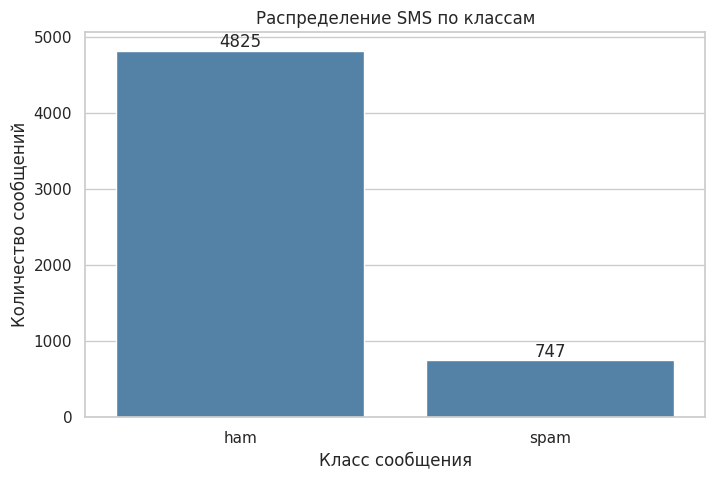

In [7]:
# Считаю количество сообщений каждого класса
class_counts = df["label"].value_counts()

# Вывожу количество и долю сообщений
print("Количество сообщений по классам:")
print(class_counts)

print("\nДоля сообщений в процентах:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

# Строю график распределения классов
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="label",
    order=["ham", "spam"],
    color="steelblue"
)

# Добавляю количество сообщений над столбцами
for container in ax.containers:
    ax.bar_label(container)

plt.title("Распределение SMS по классам")
plt.xlabel("Класс сообщения")
plt.ylabel("Количество сообщений")

plt.show()

### Вывод по распределению классов

По полученному графику понимаю, что обычных сообщений значительно больше, чем спама.

Из 5572 сообщений:
- 4825 (86,59%) относятся к классу `ham`;
- 747 (13,41%) относятся к классу `spam`.

Получается, что классы в датасете несбалансированы. Это важно учитывать при дальнейшем обучении модели, поскольку она может чаще предсказывать обычные сообщения просто потому, что их больше.

Поэтому решила использовать F1-score в качестве основной метрики качества. Также при разделении данных на обучающую и тестовую выборки будет полезно использовать стратификацию, чтобы сохранить соотношение классов.

### 5.5. Анализ длины SMS-сообщений

Дальше проверяю отличается ли длина обычных сообщений от спама.

Для этого добавляю новый столбец с количеством символов в каждом сообщении. посмотрю на основные статистики и построю график распределения длины SMS для двух классов.

Хочу выяснить можно ли использовать длину сообщения как дополнительный признак при обучении модели.

Статистика длины сообщений по классам:
        count    mean    std   min    25%    50%    75%    max
label                                                         
ham    4825.0   71.48  58.44   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.67  28.87  13.0  133.0  149.0  157.0  223.0


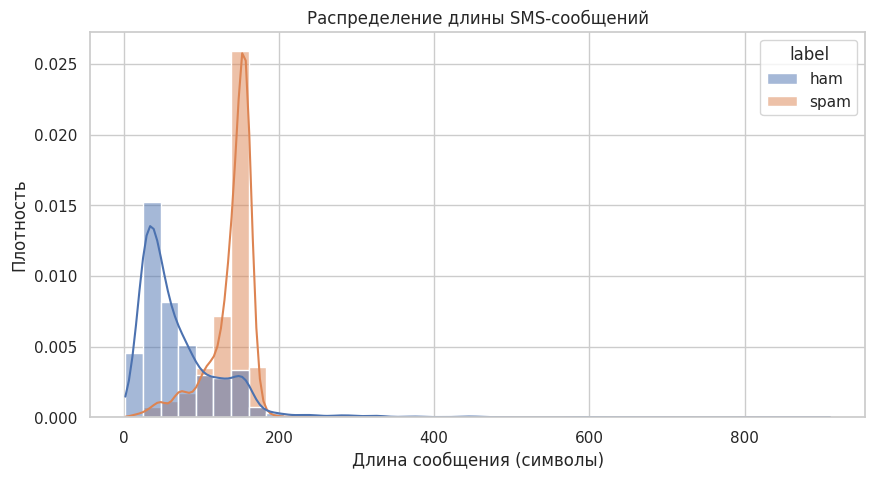

In [8]:
# Добавляю столбец с количеством символов в сообщении
df["message_length"] = df["message"].str.len()

# Сравниваю длину сообщений для каждого класса
print("Статистика длины сообщений по классам:")
print(df.groupby("label")["message_length"].describe().round(2))

# Строю гистограмму распределения длины сообщений
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="message_length",
    hue="label",
    bins=40,
    kde=True,
    stat="density",
    common_norm=False,
    alpha=0.5
)

plt.title("Распределение длины SMS-сообщений")
plt.xlabel("Длина сообщения (символы)")
plt.ylabel("Плотность")
plt.show()

**Вывод:**

После построения графика понимаю, что спам-сообщения в среднем длиннее обычных SMS.

Средняя длина обычных сообщений составляет 71 символ, а спама — примерно 139 символов. На графике видно, что большинство спам-сообщений сосредоточено примерно в диапазоне 130–160 символов, тогда как обычные сообщения чаще бывают короткими.

Получается, что длина сообщения действительно может помочь при определении спама, поэтому в дальнейшем я могу использовать её как дополнительный признак для модели.

### 5.6. Поиск выбросов в длине сообщений

Теперь я хочу посмотреть на распределение длины сообщений с другой стороны. Для этого построю boxplot, который поможет сравнить медианные значения и разброс длины сообщений в каждом классе.

Также с его помощью смогу заметить необычно длинные сообщения, которые могут потребовать дополнительного внимания при обработке данных.

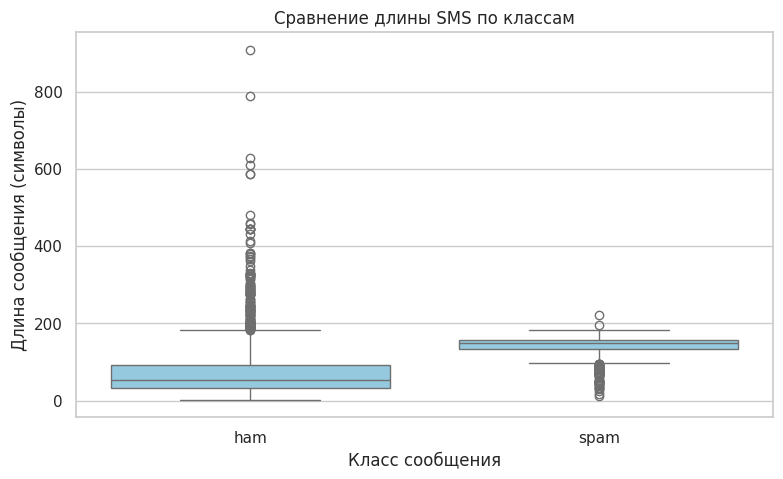

In [9]:
# Строю boxplot для сравнения длины сообщений
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="label",
    y="message_length",
    order=["ham", "spam"],
    color="skyblue"
)

plt.title("Сравнение длины SMS по классам")
plt.xlabel("Класс сообщения")
plt.ylabel("Длина сообщения (символы)")
plt.show()

**Вывод:**

После построения boxplot вижу, что у обычных сообщений намного больше выбросов по длине. Некоторые SMS достигают 910 символов, хотя большинство значительно короче.

У спама разброс длины меньше, и основная часть сообщений сосредоточена примерно в диапазоне 130–160 символов.

Решила пока не удалять эти выбросы, потому что длинные сообщения не обязательно являются ошибками в данных. Перед обучением модели их можно будет изучить подробнее.

### 5.7. Анализ количества слов в сообщениях

Теперь хочу проверить отличается ли количество слов в обычных сообщениях и спаме.

Для этого добавляю новый столбец, в котором посчитаю слова в каждом SMS. Затем сравню основные статистики для двух классов и построю график.

Так я смогу понять, есть ли ещё какие-то особенности текста, которые можно будет учитывать при обучении модели.

Статистика количества слов по классам:
        count   mean    std  min   25%   50%   75%    max
label                                                    
ham    4825.0  14.31  11.52  1.0   7.0  11.0  19.0  171.0
spam    747.0  23.91   5.78  2.0  22.0  25.0  28.0   35.0


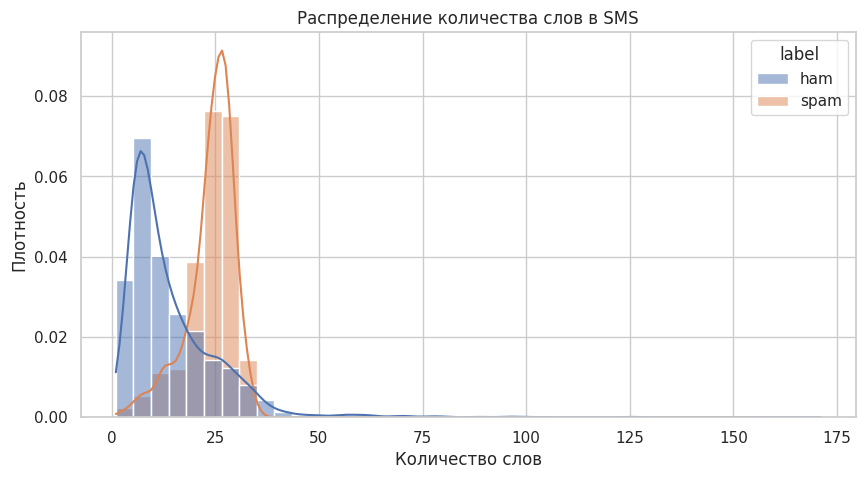

In [10]:
# Считаю количество слов в каждом сообщении
df["word_count"] = df["message"].str.split().str.len()

# Смотрю статистику количества слов по классам
print("Статистика количества слов по классам:")
print(df.groupby("label")["word_count"].describe().round(2))

# Строю гистограмму количества слов
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="label",
    bins=40,
    kde=True,
    stat="density",
    common_norm=False,
    alpha=0.5
)

plt.title("Распределение количества слов в SMS")
plt.xlabel("Количество слов")
plt.ylabel("Плотность")

plt.show()

**Вывод:**

После анализа количества слов поняла что спам-сообщения обычно содержат больше слов, чем обычные SMS.

В среднем в обычных сообщениях около 14 слов, а в спаме — около 24. На графике также видно, что у спама большинство значений сосредоточено примерно в диапазоне 20–30 слов, тогда как обычные сообщения чаще содержат меньше 15 слов.

При этом среди обычных сообщений встречаются и очень длинные тексты, максимальное количество слов достигает 171.

Получается, что количество слов, как и длина сообщения в символах, может быть полезным дополнительным признаком при определении спама.

### 5.8. Анализ связи между текстовыми признаками

Поняла что спам отличается от обычных сообщений по количеству символов и слов. Теперь хочу проверить, насколько эти два признака связаны между собой.

Для этого построю диаграмму рассеяния и посмотрю на корреляцию между длиной сообщения и количеством слов. Это поможет мне понять, насколько похожую информацию содержат эти признаки.

Корреляция между признаками:
                message_length  word_count
message_length            1.00        0.97
word_count                0.97        1.00


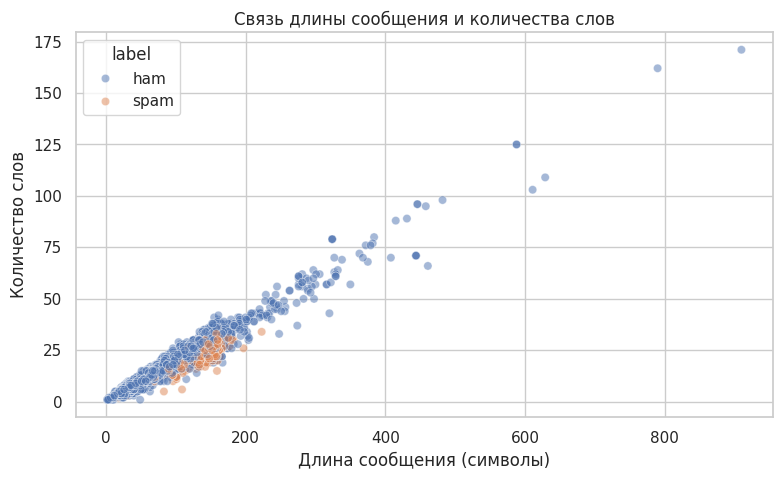

In [11]:
# Смотрю корреляцию между длиной сообщения и количеством слов
correlation = df[["message_length", "word_count"]].corr()

print("Корреляция между признаками:")
print(correlation.round(2))

# Строю диаграмму рассеяния
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="message_length",
    y="word_count",
    hue="label",
    alpha=0.5
)

plt.title("Связь длины сообщения и количества слов")
plt.xlabel("Длина сообщения (символы)")
plt.ylabel("Количество слов")

plt.show()

**Вывод:**

После построения диаграммы рассеяния заметила, что между длиной сообщения и количеством слов существует сильная положительная связь.

Коэффициент корреляции составил **0,97**, что говорит о том, что с увеличением количества символов практически всегда увеличивается и количество слов.

Также на графике видно, что обычные сообщения имеют больший разброс значений, а спам в основном сосредоточен в области примерно 100–200 символов.

Эти два признака содержат очень похожую информацию. Поэтому при дальнейшем обучении модели стоит проверить, есть ли смысл использовать оба признака одновременно или достаточно оставить один из них.

## 6. Итоговые выводы

В ходе работы я выбрала задачу определения спама в SMS-сообщениях и провела разведочный анализ датасета SMS Spam Collection.

После изучения данных я сделала несколько выводов:

1. В датасете содержится **5572 сообщения**, пропущенных значений нет, но присутствуют **403 дубликата**. Перед обучением модели я планирую удалить повторяющиеся записи.

2. Классы распределены неравномерно: **86,59% сообщений относятся к обычным SMS и только 13,41% — к спаму**. Поэтому при дальнейшем обучении я буду учитывать дисбаланс классов и использовать F1-score для оценки качества модели.

3. Спам-сообщения в среднем длиннее обычных: около **139 символов против 71**. Это позволяет предположить, что длина сообщения может быть полезным признаком для классификации.

4. Количество слов также отличается: в спаме в среднем около **24 слов**, а в обычных сообщениях — около **14**.

5. Между длиной сообщения и количеством слов обнаружена сильная корреляция — **0,97**. В дальнейшем я проверю, насколько полезно использовать оба этих признака.

6. При анализе я также обнаружила необычно длинные сообщения. Пока я решила их не удалять, поскольку они могут быть реальными SMS, а не ошибками в данных.

